In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [20]:
folder = Path("../data/raw")

ranks = [
    "iron",
    "bronze",
    "silver",
    "gold",
    "platinum",
    "emerald",
    "diamond",
    "master",
    "grandmaster",
    "challenger"
]

dfs = []

for rank in ranks:
    temp = pd.read_csv(folder / f"{rank}.csv")

    # Add the rank as the target
    temp["tier"] = rank.upper()

    dfs.append(temp)

# Combine all rank datasets
df = pd.concat(dfs, ignore_index=True)

df.head()

,match_id,puuid,team_id,win,kills,deaths,assists,cs,gold,damage,...,gold_share,gold_per_min,damage_per_min,vision_per_min,kill_participation,team_first_blood,team_first_tower,team_first_dragon,player_first_blood,tier
0,EUW1_7680198444,lORFiQwTi0sjBXeIjhYZ_tw7VUxVkAwu5aKtbIenmItshP...,200,1,2,2,7,19,13360,6434,...,0.163229,353.835890,170.401527,0.888484,0.225000,1,1,0,0,IRON
1,EUW1_7680149734,lORFiQwTi0sjBXeIjhYZ_tw7VUxVkAwu5aKtbIenmItshP...,100,1,6,6,10,16,15294,20841,...,0.193167,398.192991,542.622012,0.957079,0.457143,1,1,0,0,IRON
2,EUW1_7680120954,lORFiQwTi0sjBXeIjhYZ_tw7VUxVkAwu5aKtbIenmItshP...,200,0,5,8,8,19,10543,13260,...,0.182162,330.987496,416.259220,0.736196,0.448276,1,0,0,0,IRON
3,EUW1_7680107669,lORFiQwTi0sjBXeIjhYZ_tw7VUxVkAwu5aKtbIenmItshP...,200,0,0,5,1,21,5104,3809,...,0.129225,216.057536,161.224765,1.919707,0.071429,0,0,0,0,IRON
4,EUW1_7680091458,lORFiQwTi0sjBXeIjhYZ_tw7VUxVkAwu5aKtbIenmItshP...,200,0,3,8,6,27,9122,8519,...,0.137286,249.168612,232.701297,2.178670,0.428571,0,0,0,0,IRON


In [21]:
print("Dataset shape:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nDataset info:")
df.info()

Dataset shape:
(204847, 26)

Columns:
['match_id', 'puuid', 'team_id', 'win', 'kills', 'deaths', 'assists', 'cs', 'gold', 'damage', 'vision', 'champ', 'role', 'game_duration', 'game_creation', 'dmg_share', 'gold_share', 'gold_per_min', 'damage_per_min', 'vision_per_min', 'kill_participation', 'team_first_blood', 'team_first_tower', 'team_first_dragon', 'player_first_blood', 'tier']

Dataset info:
<class 'pandas.DataFrame'>
RangeIndex: 204847 entries, 0 to 204846
Data columns (total 26 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   match_id            204847 non-null  str    
 1   puuid               204847 non-null  str    
 2   team_id             204847 non-null  int64  
 3   win                 204847 non-null  int64  
 4   kills               204847 non-null  int64  
 5   deaths              204847 non-null  int64  
 6   assists             204847 non-null  int64  
 7   cs                  204847 non-null  int64  


In [31]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

for i, column in enumerate(df.columns):
    print(i, column)

Missing values:
match_id                0
puuid                   0
team_id                 0
win                     0
kills                   0
deaths                  0
assists                 0
cs                      0
gold                    0
damage                  0
vision                  0
champ                   0
role                  113
game_duration           0
game_creation           0
dmg_share               0
gold_share              0
gold_per_min            0
damage_per_min          0
vision_per_min          0
kill_participation      0
team_first_blood        0
team_first_tower        0
team_first_dragon       0
player_first_blood      0
tier                    0
dtype: int64

Duplicate rows:
0
0 match_id
1 puuid
2 team_id
3 win
4 kills
5 deaths
6 assists
7 cs
8 gold
9 damage
10 vision
11 champ
12 role
13 game_duration
14 game_creation
15 dmg_share
16 gold_share
17 gold_per_min
18 damage_per_min
19 vision_per_min
20 kill_participation
21 team_first_blood
22 team_fir

In [32]:
df = df.dropna(subset=["role"]).copy()

print("Dataset shape after removing missing roles:")
print(df.shape)

print("\nMissing values:")
print(df.isnull().sum().sum())

Dataset shape after removing missing roles:
(204734, 26)

Missing values:
0


In [33]:
print("Unique players:")
print(df["puuid"].nunique())

print("\nTotal rows:")
print(len(df))

print("\nAverage matches per player:")
print(round(len(df) / df["puuid"].nunique(), 2))

Unique players:
4340

Total rows:
204734

Average matches per player:
47.17


In [35]:
print("Number of different tiers per player:")
print(df.groupby("puuid")["tier"].nunique().value_counts())

Number of different tiers per player:
tier
1    4340
Name: count, dtype: int64


In [36]:
player_ranks = df.drop_duplicates("puuid")

print("Unique players per rank:")
print(player_ranks["tier"].value_counts())

Unique players per rank:
tier
GOLD           496
DIAMOND        496
PLATINUM       494
MASTER         494
IRON           491
SILVER         488
BRONZE         439
GRANDMASTER    396
EMERALD        347
CHALLENGER     199
Name: count, dtype: int64


In [23]:
print("Rank distribution:")
print(df["tier"].value_counts())

print("\nRank distribution (%):")
print((df["tier"].value_counts(normalize=True) * 100).round(2))

Rank distribution:
tier
DIAMOND        24785
MASTER         24683
PLATINUM       23867
GOLD           22891
SILVER         22856
BRONZE         20242
GRANDMASTER    19793
IRON           18588
EMERALD        17195
CHALLENGER      9947
Name: count, dtype: int64

Rank distribution (%):
tier
DIAMOND        12.10
MASTER         12.05
PLATINUM       11.65
GOLD           11.17
SILVER         11.16
BRONZE          9.88
GRANDMASTER     9.66
IRON            9.07
EMERALD         8.39
CHALLENGER      4.86
Name: proportion, dtype: float64


In [24]:
df.describe()

,team_id,win,kills,deaths,assists,cs,gold,damage,vision,game_duration,...,dmg_share,gold_share,gold_per_min,damage_per_min,vision_per_min,kill_participation,team_first_blood,team_first_tower,team_first_dragon,player_first_blood
count,204847.000000,204847.000000,204847.000000,204847.000000,204847.000000,204847.000000,204847.00000,204847.000000,204847.000000,204847.000000,...,204847.000000,204847.000000,204847.000000,204847.000000,204847.000000,204847.000000,204847.000000,204847.000000,204847.000000,204847.000000
mean,150.815487,0.526110,6.039708,5.865919,8.277895,131.612438,11911.24512,22016.903367,31.903416,1722.611696,...,0.200683,0.200133,412.862221,729.838082,1.088964,0.461928,0.495653,0.497318,0.495394,0.170713
std,49.993471,0.499319,4.857457,3.364610,6.165216,95.757122,4338.31204,13685.890259,26.456732,468.121074,...,0.087205,0.039316,97.215497,367.964985,0.802376,0.174011,0.499982,0.499994,0.499980,0.376259
min,100.000000,0.000000,0.000000,0.000000,0.000000,0.000000,500.00000,0.000000,0.000000,60.000000,...,0.000000,0.072164,136.026698,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,100.000000,0.000000,2.000000,3.000000,4.000000,32.000000,9069.00000,11849.500000,15.000000,1489.000000,...,0.141240,0.171836,339.036881,454.197916,0.590812,0.354167,0.000000,0.000000,0.000000,0.000000
50%,200.000000,1.000000,5.000000,6.000000,7.000000,145.000000,11755.00000,19785.000000,24.000000,1741.000000,...,0.198443,0.200629,407.818395,695.722056,0.827833,0.469697,0.000000,0.000000,0.000000,0.000000
75%,200.000000,1.000000,9.000000,8.000000,11.000000,212.000000,14625.00000,29448.500000,38.000000,1996.000000,...,0.254302,0.226593,476.612116,953.972162,1.222551,0.578947,1.000000,1.000000,1.000000,0.000000
max,200.000000,1.000000,43.000000,25.000000,53.000000,534.000000,39550.00000,140827.000000,254.000000,4371.000000,...,1.000000,0.385996,930.442448,3465.393877,6.086413,1.000000,1.000000,1.000000,1.000000,1.000000


In [25]:
possible_role_columns = [
    "teamPosition",
    "role",
    "position",
    "individualPosition"
]

role_column = None

for column in possible_role_columns:
    if column in df.columns:
        role_column = column
        break

if role_column:
    print("Role column:", role_column)
    print("\nRole distribution:")
    print(df[role_column].value_counts())
else:
    print("Could not automatically find the role column.")

Role column: role

Role distribution:
role
UTILITY    42757
BOTTOM     42033
MIDDLE     40189
TOP        39888
JUNGLE     39867
Name: count, dtype: int64


In [26]:
print("Rows per rank:")

for rank in ranks:
    temp = pd.read_csv(folder / f"{rank}.csv")
    print(f"{rank.upper()}: {len(temp)}")

Rows per rank:
IRON: 18588
BRONZE: 20242
SILVER: 22856
GOLD: 22891
PLATINUM: 23867
EMERALD: 17195
DIAMOND: 24785
MASTER: 24683
GRANDMASTER: 19793
CHALLENGER: 9947


In [27]:
possible_match_columns = [
    "match_id",
    "matchId",
    "gameId",
    "game_id"
]

match_column = None

for column in possible_match_columns:
    if column in df.columns:
        match_column = column
        break

if match_column:
    print("Match ID column:", match_column)

    print("\nUnique matches:")
    print(df[match_column].nunique())

    print("\nTotal rows:")
    print(len(df))
else:
    print("Could not automatically find the match ID column.")

Match ID column: match_id

Unique matches:
174477

Total rows:
204847


In [28]:
if "win" in df.columns:
    print("Win values:")
    print(df["win"].value_counts())
else:
    print("No column called 'win' found.")

Win values:
win
1    107772
0     97075
Name: count, dtype: int64


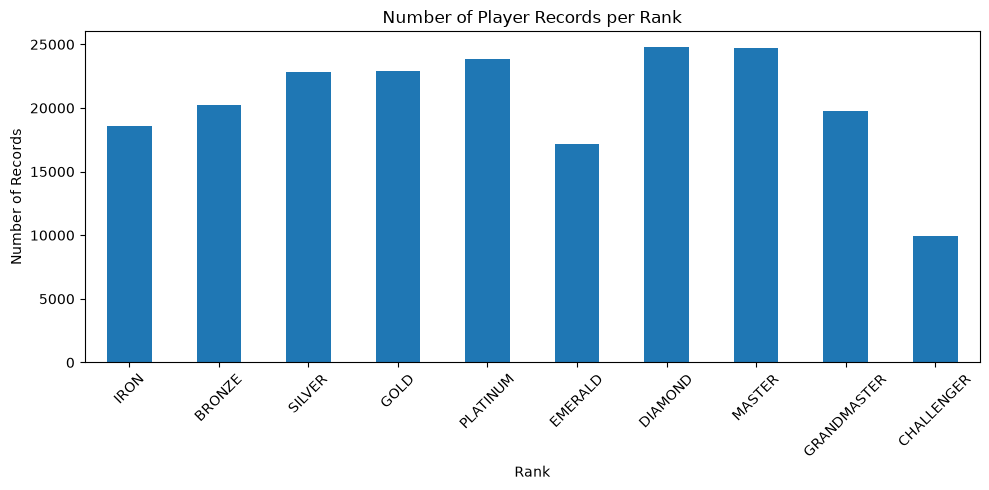

In [29]:
rank_order = [
    "IRON",
    "BRONZE",
    "SILVER",
    "GOLD",
    "PLATINUM",
    "EMERALD",
    "DIAMOND",
    "MASTER",
    "GRANDMASTER",
    "CHALLENGER"
]

df["tier"].value_counts().reindex(rank_order).plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Number of Player Records per Rank")
plt.xlabel("Rank")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()